<a href="https://colab.research.google.com/github/purinpurin11/Micas-blancas/blob/SUITE-PIAXTLA/Suite_Piaxtla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sube el archivo RT-MICA.xlsx


Saving RT-MICA.xlsx to RT-MICA.xlsx

Micas: 23   |   Rutilo válido: 135   |   Outliers Zr eliminados: 4

Se descartan Zr > 1000 ppm:


,rock,micro,Zr
28,Eclogita de granate y onfacita,Matriz,6000.406456
40,Anfibolita de granate,Inclusión,18526.083487
52,Anfibolita de granate,Matriz,1525.174671
73,Mezcla Máfico y félsico,Matriz,94005.756645


Rango P: 0.51 – 2.30 GPa
Rango T: 464.7 – 766.8 °C


## Tabla completa de pares mica–rutilo

,Roca,Microstructura,Grupo,Si,Mg,Al,Fe,Mg+Fe,Zr (ppm),iter,P (GPa),T (°C),G2 válido
0,Anfibolita de granate,Matriz,G2: Si>3.25,3.2736,0.3811,2.3308,0.1119,0.4930,52.4118,10,1.5452,516.6749,True
1,Anfibolita de granate,Matriz,G2: Si>3.25,3.2736,0.3811,2.3308,0.1119,0.4930,62.1357,10,1.5846,529.8098,True
2,Anfibolita de granate,Matriz,G2: Si>3.25,3.2736,0.3811,2.3308,0.1119,0.4930,42.4915,10,1.4984,501.0583,True
3,Anfibolita de granate,Matriz,G2: Si>3.25,3.2736,0.3811,2.3308,0.1119,0.4930,66.4790,10,1.6006,535.1457,True
4,Anfibolita de granate,Matriz,G2: Si>3.25,3.2736,0.3811,2.3308,0.1119,0.4930,53.0104,10,1.5478,517.5381,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
336,Veta félsica,Matriz,G1: Si<3.25,3.1301,0.1875,2.6419,0.0774,0.2649,84.6700,9,0.6753,515.1479,True
337,Veta félsica,Matriz,G1: Si<3.25,3.1301,0.1875,2.6419,0.0774,0.2649,65.8257,9,0.6318,496.2446,True
338,Veta félsica,Matriz,G1: Si<3.25,3.1301,0.1875,2.6419,0.0774,0.2649,109.5256,9,0.7220,535.4532,True
339,Veta félsica,Matriz,G1: Si<3.25,3.1301,0.1875,2.6419,0.0774,0.2649,95.8892,9,0.6975,524.8361,True


... (2 outputs left out)

,rock,micro,n,P_mediana_GPa,P_p16,P_p84,T_mediana_C,T_p16,T_p84
0,Anfibolita de granate,Matriz,54.0,0.772,0.699,1.590,509.279,485.434,538.292
1,Veta félsica,Matriz,287.0,0.684,0.591,0.888,500.619,480.972,524.890


## Resumen por grupo de fengita

,rock,micro,grupo,n,P_mediana_GPa,P_p16,P_p84,T_mediana_C,T_p16,T_p84
0,Anfibolita de granate,Matriz,G1: Si<3.25,36.0,0.738,0.681,0.801,498.346,481.104,519.506
1,Anfibolita de granate,Matriz,G2: Si>3.25,18.0,1.590,1.539,1.660,531.679,514.664,554.913
2,Veta félsica,Matriz,G1: Si<3.25,287.0,0.684,0.591,0.888,500.619,480.972,524.890



Rango de P por grupo:
               min  median    max
grupo                            
G1: Si<3.25  0.514   0.696  1.411
G2: Si>3.25  1.498   1.590  2.295

Rango de T por grupo:
               min  median    max
grupo                            
G1: Si<3.25  464.7   500.0  716.2
G2: Si>3.25  501.1   531.7  766.8


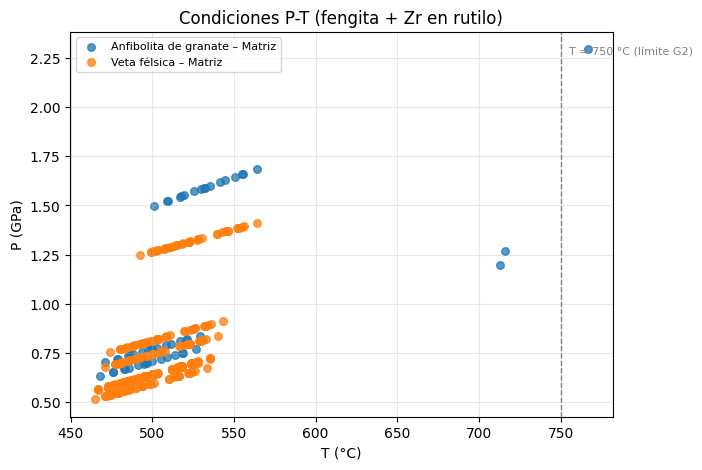

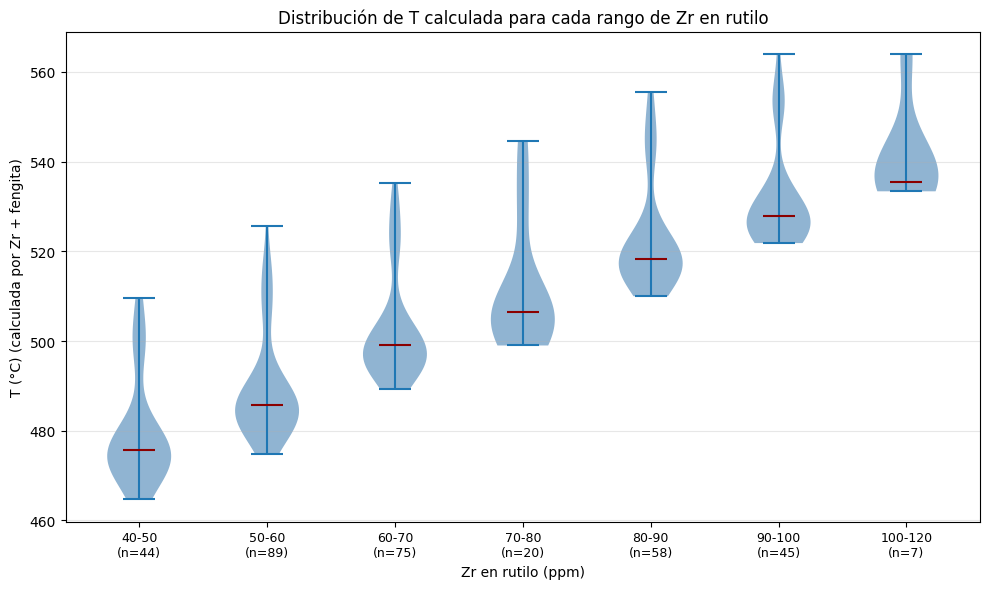


Excel generado: RT_MICA_resultados.xlsx
Hojas: Resumen_PT, Proceso_iterativo, Resumen_roca, Resumen_grupo, Outliers_Zr
Cada hoja incluye la tabla; 'Resumen_PT' además las dos figuras.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ============================================================
# Cálculo P-T detallado (CORREGIDO) + Excel + Violín
#   · Barómetro de fengita: Kamzolkin et al. (2016), ec. (4) y (5)
#   · Termómetro Zr en rutilo
# Google Colab
# ============================================================

!pip -q install openpyxl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. Subir y leer Excel
# ------------------------------------------------------------
print("Sube el archivo RT-MICA.xlsx")
uploaded = files.upload()
path = next(iter(uploaded))

SHEET = "APFU_mica_blanca_11O"

# ---- Filtro de outliers de Zr en rutilo --------------------
# Zr = 6000, 18526 y 94005 ppm son inclusiones de circón,
# no Zr en solución sólida. Todo Zr > ZR_MAX_PPM se descarta.
ZR_MAX_PPM = 1000
# ------------------------------------------------------------

raw = pd.read_excel(path, sheet_name=SHEET, header=None)
df  = raw.iloc[2:].copy().reset_index(drop=True)
df.columns = [
    "rock_mica", "micro_mica", "Si", "Mg", "Al", "Fe", "c6", "c7",
    "rock_rt",   "micro_rt",   "Zr"
]
for col in ["Si", "Mg", "Al", "Fe", "Zr"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# --- mica blanca ---
mica = (df[["rock_mica", "micro_mica", "Si", "Mg", "Al", "Fe"]]
        .dropna(subset=["Si", "Mg", "Al", "Fe"])
        .rename(columns={"rock_mica": "rock", "micro_mica": "micro"})
        .copy())
mica["MgFe"] = mica["Mg"] + mica["Fe"]

# --- rutilo ---
rut_all = (df[["rock_rt", "micro_rt", "Zr"]]
           .dropna(subset=["Zr"])
           .rename(columns={"rock_rt": "rock", "micro_rt": "micro"})
           .copy())
rut_all = rut_all[rut_all["Zr"] > 0]          # fix: antes decía "tut_all"

outliers = rut_all[rut_all["Zr"] > ZR_MAX_PPM].copy()
rut      = rut_all[rut_all["Zr"] <= ZR_MAX_PPM].copy()

print(f"\nMicas: {len(mica)}   |   Rutilo válido: {len(rut)}   "
      f"|   Outliers Zr eliminados: {len(outliers)}")
if len(outliers) > 0:
    print(f"\nSe descartan Zr > {ZR_MAX_PPM} ppm:")
    display(outliers)

# ------------------------------------------------------------
# 2. Fórmulas
# ------------------------------------------------------------
R = 8.31447  # J/(mol·K)

def P_fengita(T_C, Si, Al, MgFe):
    """Kamzolkin et al. (2016). G1 = ec. (4), G2 = ec. (5)."""
    if Si < 3.25:
        num = (0.023*T_C + 5.99*Si + 1.76*Al
               + 12.89*MgFe - 31.91)            # ← +12.89 (Mg+Fe)
        return num/10.0, num, "ec. (4)  G1: Si<3.25"
    else:
        num = (0.030*T_C + 19.21*Si - 2.91*Al
               + 2.17*MgFe - 57.22)
        return num/10.0, num, "ec. (5)  G2: Si>3.25"

def T_rutile(P_GPa, C_ppm):
    """T(°C) por Zr en rutilo."""
    P_bar = P_GPa * 10000.0
    num   = 71360.0 + 0.378*P_bar - 0.130*C_ppm
    den   = 130.66 - R*np.log(C_ppm)
    T     = num/den - 273.1
    return T, num, den, P_bar

def solve_PT_detallado(Si, Al, MgFe, Zr_ppm,
                       P0=1.0, T0=600.0,
                       max_iter=50, tol_P=1e-8, tol_T=1e-4):
    P, T = P0, T0
    pasos = []
    for it in range(1, max_iter+1):
        T_new, numT, denT, Pbar = T_rutile(P, Zr_ppm)
        P_new, numP, eq         = P_fengita(T_new, Si, Al, MgFe)
        pasos.append({
            "iter": it, "P_in_GPa": P, "Pbar": Pbar,
            "T_calc_C": T_new, "num_T": numT, "den_T": denT,
            "P_calc_GPa": P_new, "num_P": numP, "eq": eq,
            "dT": abs(T_new - T), "dP": abs(P_new - P),
        })
        if abs(T_new - T) < tol_T and abs(P_new - P) < tol_P:
            return P_new, T_new, pasos
        P, T = P_new, T_new
    return P, T, pasos

# ------------------------------------------------------------
# 3. Emparejar mica–rutilo por (roca, microstructura)
# ------------------------------------------------------------
all_pairs = []
for (rock, micro), m in mica.groupby(["rock", "micro"], dropna=False):
    r = rut[(rut["rock"] == rock) & (rut["micro"] == micro)]
    if len(r) == 0:
        continue
    comb = (m.assign(_k=1)
              .merge(r.assign(_k=1), on="_k",
                     suffixes=("_mica", "_rut"))
              .drop(columns="_k"))
    comb["rock"]  = rock
    comb["micro"] = micro
    all_pairs.append(comb)

pairs = pd.concat(all_pairs, ignore_index=True) if all_pairs else pd.DataFrame()
if len(pairs) == 0:
    raise SystemExit("No hay pares mica–rutilo con la misma roca+microstructura.")

# ------------------------------------------------------------
# 4. Calcular P-T de cada par
# ------------------------------------------------------------
P_list, T_list, grupo_list, iter_list = [], [], [], []
procesos = {}

for idx, row in pairs.iterrows():
    P, T, pasos = solve_PT_detallado(row["Si"], row["Al"], row["MgFe"], row["Zr"])
    P_list.append(P); T_list.append(T)
    grupo_list.append("G1: Si<3.25" if row["Si"] < 3.25 else "G2: Si>3.25")
    iter_list.append(len(pasos))
    procesos[idx] = pasos

pairs["P_GPa"]  = P_list
pairs["T_C"]    = T_list
pairs["grupo"]  = grupo_list
pairs["n_iter"] = iter_list
pairs["G2_valida"] = ~((pairs["Si"] >= 3.25) & (pairs["T_C"] >= 750))

assert (pairs["P_GPa"] > 0).all(), "Presiones no positivas."
print(f"Rango P: {pairs['P_GPa'].min():.2f} – {pairs['P_GPa'].max():.2f} GPa")
print(f"Rango T: {pairs['T_C'].min():.1f} – {pairs['T_C'].max():.1f} °C")

# ------------------------------------------------------------
# 5. Tabla completa de resultados
# ------------------------------------------------------------
cols = ["rock","micro","grupo","Si","Mg","Al","Fe","MgFe","Zr",
        "n_iter","P_GPa","T_C","G2_valida"]
tabla = pairs[cols].copy()
tabla.columns = ["Roca","Microstructura","Grupo","Si","Mg","Al","Fe",
                 "Mg+Fe","Zr (ppm)","iter","P (GPa)","T (°C)","G2 válido"]

display(Markdown("## Tabla completa de pares mica–rutilo"))
display(tabla.round(4))

# ------------------------------------------------------------
# 6. Proceso iterativo de todos los pares
# ------------------------------------------------------------
filas = []
for idx, pasos_i in procesos.items():
    row = pairs.loc[idx]
    for p in pasos_i:
        filas.append({
            "Roca": row["rock"], "Microstructura": row["micro"],
            "Si": row["Si"], "Grupo": row["grupo"], "Zr": row["Zr"],
            "iter": p["iter"],
            "P_in (GPa)": p["P_in_GPa"],
            "T_calc (°C)": p["T_calc_C"],
            "P_calc (GPa)": p["P_calc_GPa"],
            "ΔT (°C)": p["dT"], "ΔP (GPa)": p["dP"],
        })
proceso_df = pd.DataFrame(filas)

# ------------------------------------------------------------
# 7. Resúmenes
# ------------------------------------------------------------
def resumen(g):
    return pd.Series({
        "n": len(g),
        "P_mediana_GPa": g["P_GPa"].median(),
        "P_p16": g["P_GPa"].quantile(0.16),
        "P_p84": g["P_GPa"].quantile(0.84),
        "T_mediana_C":   g["T_C"].median(),
        "T_p16":         g["T_C"].quantile(0.16),
        "T_p84":         g["T_C"].quantile(0.84),
    })

resumen_rock  = pairs.groupby(["rock","micro"]).apply(resumen).reset_index()
resumen_grupo = pairs.groupby(["rock","micro","grupo"]).apply(resumen).reset_index()

display(Markdown("## Resumen global por roca + microstructura"))
display(resumen_rock.round(3))
display(Markdown("## Resumen por grupo de fengita"))
display(resumen_grupo.round(3))

print("\nRango de P por grupo:")
print(pairs.groupby("grupo")["P_GPa"].agg(["min","median","max"]).round(3))
print("\nRango de T por grupo:")
print(pairs.groupby("grupo")["T_C"].agg(["min","median","max"]).round(1))

# ------------------------------------------------------------
# 8. Gráfico P-T (scatter)
# ------------------------------------------------------------
fig_pt, ax = plt.subplots(figsize=(7, 5))
for (rock, micro), g in pairs.groupby(["rock","micro"]):
    ax.scatter(g["T_C"], g["P_GPa"], s=30, alpha=0.75,
               label=f"{rock} – {micro}")
ax.axvline(750, ls="--", c="gray", lw=1)
ax.text(755, ax.get_ylim()[1]*0.95, "T = 750 °C (límite G2)",
        fontsize=8, color="gray")
ax.set_xlabel("T (°C)"); ax.set_ylabel("P (GPa)")
ax.set_title("Condiciones P-T (fengita + Zr en rutilo)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="best")
plt.show()
fig_pt.savefig("scatter_PT.png", dpi=150, bbox_inches="tight")

# ------------------------------------------------------------
# 9. DIAGRAMA DE VIOLÍN: Zr (ppm) vs T (°C)
# ------------------------------------------------------------
# Se agrupa Zr en intervalos y para cada intervalo se muestra
# la distribución de T calculada (una T por cada par mica-rutilo).
zr_bins   = [40, 50, 60, 70, 80, 90, 100, 120, 200]
zr_labels = ["40-50", "50-60", "60-70", "70-80",
             "80-90", "90-100", "100-120", ">120"]
pairs["Zr_bin"] = pd.cut(pairs["Zr"], bins=zr_bins,
                         labels=zr_labels, include_lowest=True)

fig_v, ax_v = plt.subplots(figsize=(10, 6))

data_v, pos_v, lab_v = [], [], []
for i, lab in enumerate(zr_labels, start=1):
    vals = pairs.loc[pairs["Zr_bin"] == lab, "T_C"].dropna().values
    if len(vals) >= 2:                         # violín necesita ≥2 puntos
        data_v.append(vals)
        pos_v.append(i)
        lab_v.append(f"{lab}\n(n={len(vals)})")

vp = ax_v.violinplot(data_v, positions=pos_v,
                     showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("steelblue")
    body.set_alpha(0.6)
vp["cmedians"].set_color("darkred")

ax_v.set_xticks(pos_v)
ax_v.set_xticklabels(lab_v, rotation=0, fontsize=9)
ax_v.set_xlabel("Zr en rutilo (ppm)")
ax_v.set_ylabel("T (°C) (calculada por Zr + fengita)")
ax_v.set_title("Distribución de T calculada para cada rango de Zr en rutilo")
ax_v.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()
fig_v.savefig("violin_T_vs_Zr.png", dpi=150, bbox_inches="tight")

# ------------------------------------------------------------
# 10. Exportar Excel con varias hojas + imágenes
# ------------------------------------------------------------
XLSX = "RT_MICA_resultados.xlsx"

with pd.ExcelWriter(XLSX, engine="openpyxl") as writer:
    # --- Hoja 1: tabla final P-T ---
    tabla.round(4).to_excel(writer, sheet_name="Resumen_PT", index=False)
    # --- Hoja 2: proceso iterativo completo ---
    proceso_df.round(5).to_excel(writer, sheet_name="Proceso_iterativo",
                                 index=False)
    # --- Hoja 3: resumen por roca+micro ---
    resumen_rock.round(3).to_excel(writer, sheet_name="Resumen_roca",
                                   index=False)
    # --- Hoja 4: resumen por grupo de fengita ---
    resumen_grupo.round(3).to_excel(writer, sheet_name="Resumen_grupo",
                                    index=False)
    # --- Hoja 5: outliers de Zr eliminados ---
    outliers.to_excel(writer, sheet_name="Outliers_Zr", index=False)

    # --- Embed imágenes en la hoja "Resumen_PT" ---
    from openpyxl.drawing.image import Image as XLImage
    ws = writer.sheets["Resumen_PT"]
    nrows = len(tabla) + 3
    ws.add_image(XLImage("scatter_PT.png"),     f"A{nrows}")
    ws.add_image(XLImage("violin_T_vs_Zr.png"), f"P{nrows}")

print(f"\nExcel generado: {XLSX}")
print("Hojas: Resumen_PT, Proceso_iterativo, Resumen_roca, "
      "Resumen_grupo, Outliers_Zr")
print("Cada hoja incluye la tabla; 'Resumen_PT' además las dos figuras.")

# Descargar el Excel
files.download(XLSX)

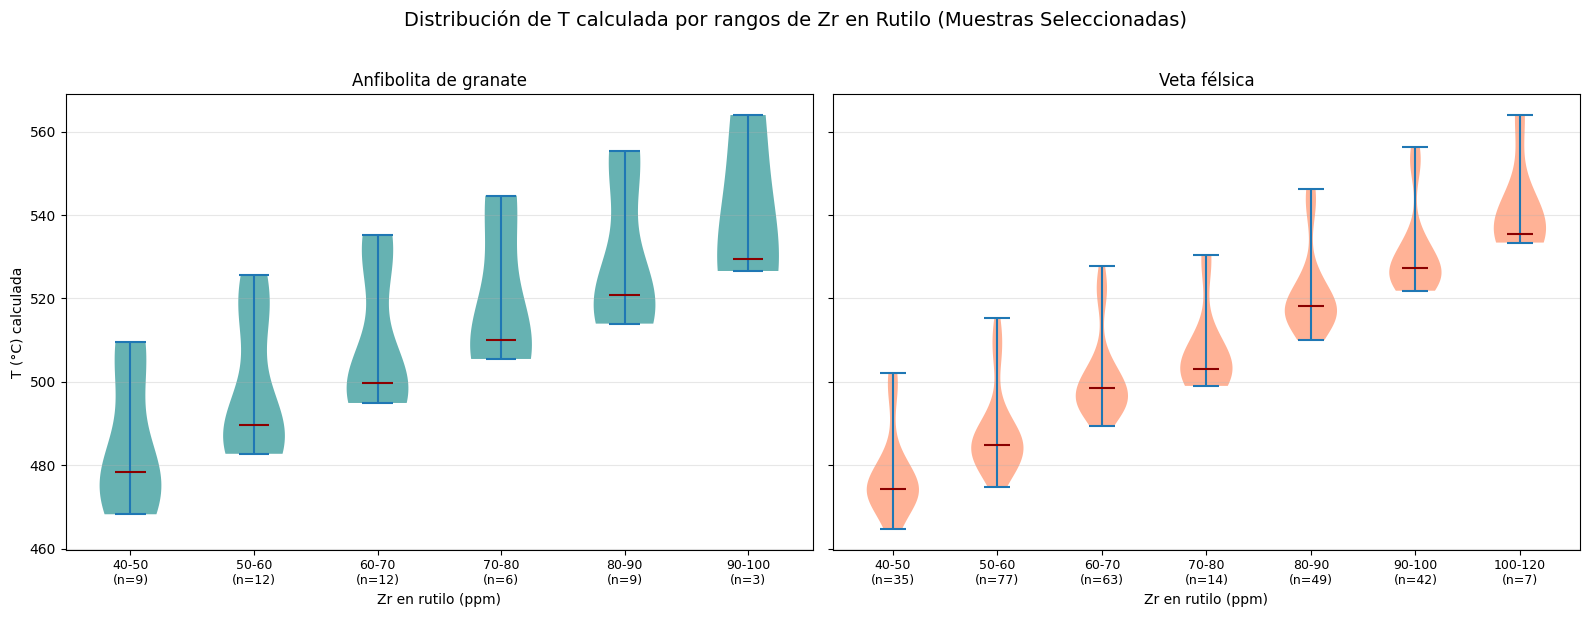

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filtrar únicamente las rocas indicadas: Anfibolita de granate y Veta félsica
rocas_interes = ['Anfibolita de granate', 'Veta félsica']
df_filtrado = pairs[pairs['rock'].isin(rocas_interes)].copy()

# Crear los bins de Zr de forma consistente con el gráfico anterior
zr_bins = [40, 50, 60, 70, 80, 90, 100, 120, 200]
zr_labels = ["40-50", "50-60", "60-70", "70-80", "80-90", "90-100", "100-120", ">120"]
df_filtrado["Zr_bin"] = pd.cut(df_filtrado["Zr"], bins=zr_bins, labels=zr_labels, include_lowest=True)

# Configurar la figura con dos subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, roca in zip(axes, rocas_interes):
    df_roca = df_filtrado[df_filtrado['rock'] == roca]

    # Recolectar datos de temperatura para cada rango de Zr existente en esta roca
    data_v, pos_v, lab_v = [], [], []
    for i, lab in enumerate(zr_labels, start=1):
        vals = df_roca.loc[df_roca["Zr_bin"] == lab, "T_C"].dropna().values
        if len(vals) >= 2:  # El diagrama de violín requiere al menos 2 puntos
            data_v.append(vals)
            pos_v.append(i)
            lab_v.append(f"{lab}\n(n={len(vals)})")

    if len(data_v) > 0:
        vp = ax.violinplot(data_v, positions=pos_v, showmedians=True, showextrema=True)
        for body in vp["bodies"]:
            body.set_facecolor("teal" if roca == 'Anfibolita de granate' else "coral")
            body.set_alpha(0.6)
        vp["cmedians"].set_color("darkred")

        ax.set_xticks(pos_v)
        ax.set_xticklabels(lab_v, fontsize=9)
    else:
        ax.text(0.5, 0.5, "Sin datos suficientes", ha='center', va='center')

    ax.set_xlabel("Zr en rutilo (ppm)")
    ax.set_title(f"{roca}")
    ax.grid(alpha=0.3, axis="y")

axes[0].set_ylabel("T (°C) calculada")
fig.suptitle("Distribución de T calculada por rangos de Zr en Rutilo (Muestras Seleccionadas)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Guardar la figura
fig.savefig("violin_T_vs_Zr_filtrado.png", dpi=150, bbox_inches="tight")